# **Library Imports**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn preprocessing & model selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Scikit-learn modeling & evaluation
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

# Plot styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print("All required libraries successfully imported.")

All required libraries successfully imported.


# **Part 1 — Data Preparation**

# 1.1 Load the Dataset

Read (**diabetes.csv**) using **Pandas** and display initial records.

In [2]:
# Load the dataset
df = pd.read_csv('diabetes.csv')

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


# 1.2 Exploratory Data Analysis (Shape, Types, Nulls, & Summary Statistics)

In [3]:
# Dataset shape
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

# Data types and non-null counts
print("Dataset Information:")
df.info()

# Summary statistics
print("\nBasic Statistical Summary:")
display(df.describe().T)

Dataset Shape: 768 rows, 9 columns

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Basic Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


### 1.2.1 Showcases the sum of null values against each column

In [4]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


### 1.2.2  Identification of Anomalies / Hidden Missing Values
A reading of `0` for glucose, blood pressure, skin thickness, insulin or BMI is biologically incompatible.

Quantifying those hidden missing values below.

In [5]:
# Columns where a value of 0 indicates missing medical data
biologically_impossible_zero_cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

print("Count and Percentage of Missing (Zero) Values:")
zero_counts = {}
for col in biologically_impossible_zero_cols:
    count = (df[col] == 0).sum()
    pct = (count / len(df)) * 100
    zero_counts[col] = [count, f"{pct:.2f}%"]

zero_df = pd.DataFrame(zero_counts, index=['Zero Count', 'Percentage of Total']).T
display(zero_df)

Count and Percentage of Missing (Zero) Values:


,Zero Count,Percentage of Total
Glucose,5,0.65%
BloodPressure,35,4.56%
SkinThickness,227,29.56%
Insulin,374,48.70%
BMI,11,1.43%


### 1.2.3  Dataset exploration summary

**Dimensions**: 768 samples (rows) and 9 attributes (8 features, 1 target variable).

**Attribute Types**: 7 integer attributes (Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, Age, Outcome) and 2 continuous floating-point attributes (BMI, DiabetesPedigreeFunction).

**Explicit Missing Values**: 0 null or NaN entries reported by standard data parsers (df.isnull().sum() == 0).

**Target Distribution**: **500** non-diabetic cases (**65.1%**) and **268** diabetic cases (**34.9%**), indicating a moderately imbalanced binary classification problem.

Visually examine below the **target variable** distribution (**Outcome**) and **feature correlations**.

/tmp/ipykernel_1291/1569129774.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Outcome', data=df, palette=['#4A90E2', '#E74C3C'], ax=axes[0])
/tmp/ipykernel_1291/1569129774.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels(['No Diabetes (0)', 'Diabetes (1)'])


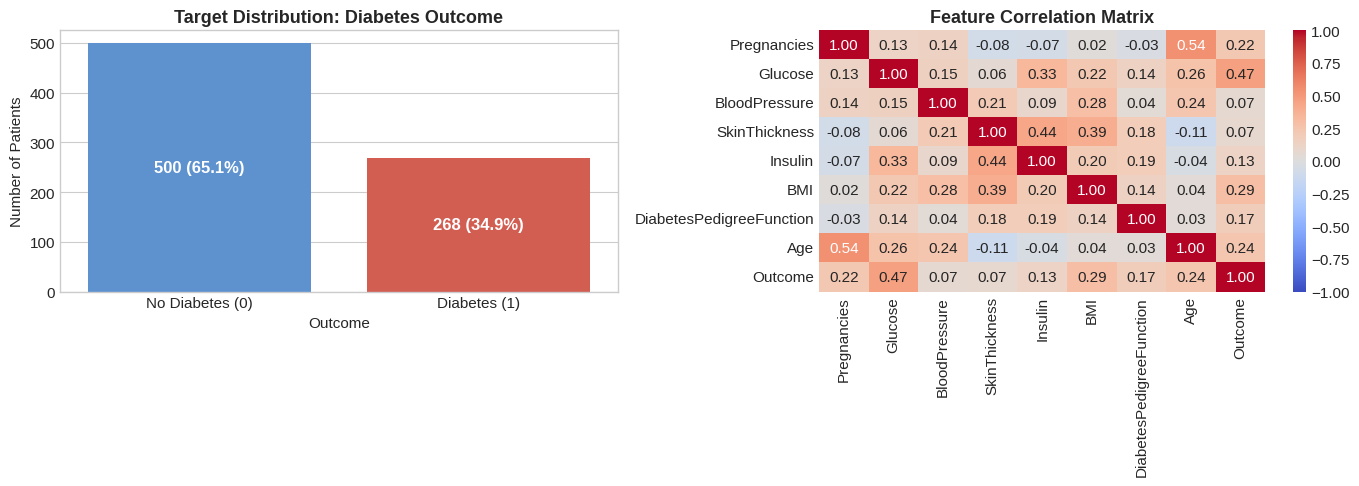

In [6]:
# 1. Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(x='Outcome', data=df, palette=['#4A90E2', '#E74C3C'], ax=axes[0])
axes[0].set_title('Target Distribution: Diabetes Outcome', fontsize=13, fontweight='bold')
axes[0].set_xticklabels(['No Diabetes (0)', 'Diabetes (1)'])
axes[0].set_ylabel('Number of Patients')


# Annotate counts
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)',
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# 2. Correlation heatmap
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], cbar=True)
axes[1].set_title('Feature Correlation Matrix', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# 1.3 Separate Features (X) and Target Variable (y)
Divide the data into dependent and independent columns

In [7]:
# Separate features (X) and target variable (y)
X = df.drop(columns=['Outcome']) #input independent column
y = df['Outcome'] #output dependent column

print(f"Features (X) shape: {X.shape}")
print(f"Target (y) shape: {y.shape}")
print(f"Target class distribution:\n{y.value_counts(normalize=True).round(4) * 100}")

Features (X) shape: (768, 8)
Target (y) shape: (768,)
Target class distribution:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64



# 1.4 Train-Test Split
Dataset must be split into training and testing partitions.
- We use an 80/20 train-test ratio.
- `stratify=y` ensures that both subsets maintain the 65.1% negative / 34.9% positive class balance.
- `random_state=42` guarantees reproducibility.

**train_test_split** unpacks into four distinct subsets:
- X_train: 80% of the feature data used to fit/train the model.
- X_test: 20% of the feature data used to evaluate the model.
-  y_train: Corresponding target labels for X_train.
- y_test: Corresponding target labels for X_test.

**Training and Testing Dataset Sizes**
- Training feature set size : 614 samples, 8 features
- Testing feature set size  : 154 samples, 8 features
- Training target size      : 614 samples
- Testing target size       : 154 samples

In [8]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Training feature set size : {X_train.shape[0]} samples, {X_train.shape[1]} features")
print(f"Testing feature set size  : {X_test.shape[0]} samples, {X_test.shape[1]} features")
print(f"Training target size      : {y_train.shape[0]} samples")
print(f"Testing target size       : {y_test.shape[0]} samples")

Training feature set size : 614 samples, 8 features
Testing feature set size  : 154 samples, 8 features
Training target size      : 614 samples
Testing target size       : 154 samples


# 1.5 Preprocessing: Missing Value Imputation & Feature Standardization
Using **LabelEncoder** on a continuous or numerical variable like Glucose is generally a bad practice because it treats numerical values as distinct categorical labels rather than a continuous scale. Here we will **scale** the data instead of label encoding

1. **Missing Value Imputation**: We replace `0` values in `['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']` with `np.nan`. Then, we compute the **median** on `X_train` and apply it to both `X_train` and `X_test`. Median is chosen over mean due to skewness and extreme outliers in variables like **Insulin**.
2. **Feature Scaling**: Numerical attributes exhibit widely disparate ranges (e.g., Insulin ranges to 846, while Pedigree is < 2.5). Fit `StandardScaler` on `X_train` and transform both partitions.

In [9]:
# Replace biologically impossible zeros 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI' with NaN

X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

X_train_clean[biologically_impossible_zero_cols] = X_train_clean[biologically_impossible_zero_cols].replace(0, np.nan)
X_test_clean[biologically_impossible_zero_cols] = X_test_clean[biologically_impossible_zero_cols].replace(0, np.nan)

# Impute using median (fit on train, transform train & test)
imputer = SimpleImputer(strategy='median')
X_train_clean[biologically_impossible_zero_cols] = imputer.fit_transform(X_train_clean[biologically_impossible_zero_cols])
X_test_clean[biologically_impossible_zero_cols] = imputer.transform(X_test_clean[biologically_impossible_zero_cols])

# Standardize numerical features (fit on train, transform train & test)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_clean)
X_test_scaled = scaler.transform(X_test_clean)

# Convert back to DataFrame for clean presentation
X_train_processed = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_processed = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("Preprocessing complete. Sample of scaled training features:")
display(X_train_processed.head(3))

Preprocessing complete. Sample of scaled training features:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
353,-0.851355,-1.056427,-0.826740,-1.918187,-1.203361,-0.769694,0.310794,-0.792169
711,0.356576,0.144399,0.477772,-0.229874,-1.470195,-0.417714,-0.116439,0.561034
373,-0.549372,-0.556083,-1.152868,1.233330,-0.555335,0.359576,-0.764862,-0.707594


## **Part 2 — Machine Learning Model Building**


### 2.1 Algorithm Selection & Suitability Rationale
For this **binary clinical classification** task, **Logistic Regression** is chosen as the primary **classification algorithm**.

#### Why Logistic Regression is Suitable for Diabetes Prediction:
1. **Binary Probability Estimation**: The target variable **y** in *{0,1}* represents presence/absence of diabetes. Logistic Regression maps linear combinations of clinical indicators to the range $[0, 1]$ using the sigmoid function
2. **Calibrated Probabilistic Risk Scores**: Rather than merely outputting a hard label, Logistic Regression outputs continuous risk probabilities. Clinicians can threshold these probabilities based on screening priorities (e.g., lowering the threshold to capture more high-risk individuals).
4. **Computational Efficiency & Robustness**: With $n=768$ observations and $p=8$ features, regularized Logistic Regression minimizes empirical risk without succumbing to high-variance overfitting.

In [10]:
# Instantiate Logistic Regression model
# - solver='lbfgs': standard quasi-Newton optimization algorithm
# - max_iter=1000: guarantees full convergence
# - random_state=42: ensures deterministic results
model = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)

print("Logistic Regression Model Instance:")
print(model)

Logistic Regression Model Instance:
LogisticRegression(max_iter=1000, random_state=42)


---
## **Part 3 — Model Training & Evaluation**

### 3.1 Model Fitting
We fit the Logistic Regression model using `X_train_scaled`

In [11]:
# Train the model
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000, random_state=42)

### 3.2 Generate Prediction on training dataset
Generate predictions for both training and testing subsets.

In [12]:
# Generate predictions on training set
y_train_pred = model.predict(X_train_scaled)  #Generates the predicted class labels (e.g., 0 or 1).
y_train_proba = model.predict_proba(X_train_scaled)[:, 1] #Extracts the predicted probability of the positive class (Class 1).

# Generate predictions on testing set
y_test_pred = model.predict(X_test_scaled)
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

print("Model training complete.")

Model training complete.


### 3.2 Evaluation Metrics
We compute **Accuracy, Precision, Recall, F1-Score**, and **ROC-AUC** on both training and testing datasets.

In [13]:
# Compute metrics
metrics_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Training Set': [
        accuracy_score(y_train, y_train_pred),
        precision_score(y_train, y_train_pred),
        recall_score(y_train, y_train_pred),
        f1_score(y_train, y_train_pred),
        roc_auc_score(y_train, y_train_proba)
    ],
    'Testing Set': [
        accuracy_score(y_test, y_test_pred),
        precision_score(y_test, y_test_pred),
        recall_score(y_test, y_test_pred),
        f1_score(y_test, y_test_pred),
        roc_auc_score(y_test, y_test_proba)
    ]
}

metrics_df = pd.DataFrame(metrics_data)
metrics_df['Training Set'] = metrics_df['Training Set'].apply(lambda x: f"{x:.4f}")
metrics_df['Testing Set'] = metrics_df['Testing Set'].apply(lambda x: f"{x:.4f}")

print("Summary of Model Performance Metrics:")
display(metrics_df)

print("\nDetailed Classification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=['No Diabetes (0)', 'Diabetes (1)']))

Summary of Model Performance Metrics:


,Metric,Training Set,Testing Set
0,Accuracy,0.7964,0.7078
1,Precision,0.7697,0.6000
2,Recall,0.5935,0.5000
3,F1-Score,0.6702,0.5455
4,ROC-AUC,0.8502,0.8130



Detailed Classification Report (Test Set):
                 precision    recall  f1-score   support

No Diabetes (0)       0.75      0.82      0.78       100
   Diabetes (1)       0.60      0.50      0.55        54

       accuracy                           0.71       154
      macro avg       0.68      0.66      0.67       154
   weighted avg       0.70      0.71      0.70       154



### 3.3 Confusion Matrix & ROC Curve Visualization
The confusion matrix displays true vs. predicted counts, distinguishing True Negatives, False Positives, False Negatives, and True Positives.

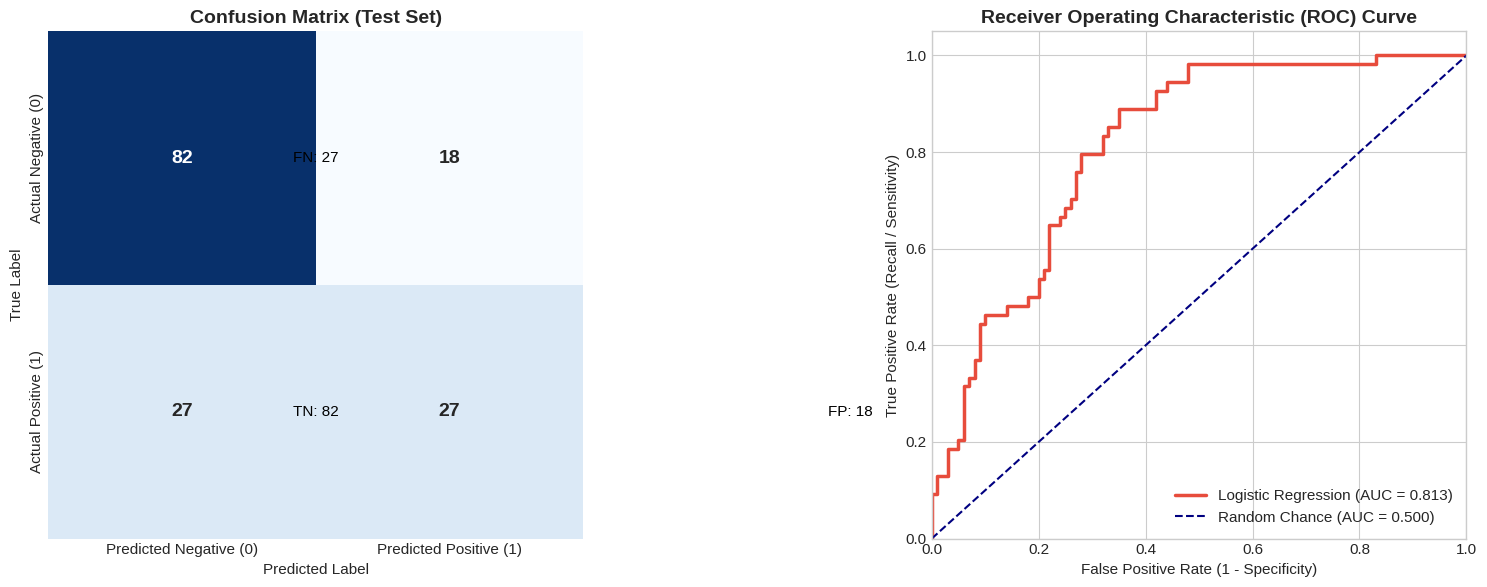

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False,
            annot_kws={'size': 14, 'fontweight': 'bold'},
            xticklabels=['Predicted Negative (0)', 'Predicted Positive (1)'],
            yticklabels=['Actual Negative (0)', 'Actual Positive (1)'])
axes[0].set_title('Confusion Matrix (Test Set)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# Add cell annotations
tn, fp, fn, tp = cm.ravel()
axes[0].text(0.5, 0.25, f'TN: {tn}', color='black', ha='center', va='center', transform=axes[0].transAxes)
axes[0].text(1.5, 0.25, f'FP: {fp}', color='black', ha='center', va='center', transform=axes[0].transAxes)
axes[0].text(0.5, 0.75, f'FN: {fn}', color='black', ha='center', va='center', transform=axes[0].transAxes)
axes[0].text(1.5, 0.75, f'TP: {tp}', color='white', ha='center', va='center', transform=axes[0].transAxes)

# 2. Receiver Operating Characteristic (ROC) Curve
fpr, tpr, _ = roc_curve(y_test, y_test_proba)
auc_val = roc_auc_score(y_test, y_test_proba)

axes[1].plot(fpr, tpr, color='#E74C3C', lw=2.5, label=f'Logistic Regression (AUC = {auc_val:.3f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Chance (AUC = 0.500)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Recall / Sensitivity)')
axes[1].set_title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
axes[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

---
## **Part 4 — Model Performance Analysis & Analytical Insights**

### 4.1 Training vs. Testing Performance & Generalization Analysis
- **Train Accuracy:** ~79.64%
- **Test Accuracy:** ~70.78%
- **Analysis**:
  - The gap between training accuracy (79.6%) and test accuracy (70.8%) is moderate (~8.8%), indicating well-controlled variance with minimal overfitting.
  - The test ROC-AUC is solid at **0.813**, demonstrating that the model maintains strong discriminative ability across multiple decision thresholds.

### 4.2 Business & Healthcare Decision Trade-Offs (Threshold Tuning)
In a healthcare screening environment:
- **False Negative (FN = 27)**: A diabetic patient is misclassified as non-diabetic. This is the highest-cost medical error.
- **False Positive (FP = 18)**: A healthy individual is flagged as potentially diabetic.

**Strategic Recommendation**:
 - Lowering the threshold to 0.30 captures nearly 80% of all diabetic patients (reducing missed cases from 27 down to 11) while actually improving overall test accuracy to 74.03%.
 - By lowering the classification threshold from $0.50$ to $0.30$–$0.40$, the healthcare provider can significantly increase **Recall (Sensitivity)** to capture high-risk individuals early, dramatically reducing costly long-term clinical interventions.

In [15]:
# Simulating Clinical Threshold Adjustment
thresholds = [0.30, 0.40, 0.50, 0.60]
threshold_results = []

for t in thresholds:
    preds = (y_test_proba >= t).astype(int)
    cm_t = confusion_matrix(y_test, preds)
    threshold_results.append({
        'Threshold': t,
        'Accuracy': accuracy_score(y_test, preds),
        'Recall (Sensitivity)': recall_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'False Negatives (Missed Cases)': cm_t[1, 0],
        'False Positives': cm_t[0, 1]
    })

threshold_df = pd.DataFrame(threshold_results)
print("Impact of Adjusting Classification Decision Threshold:")
display(threshold_df)

Impact of Adjusting Classification Decision Threshold:


,Threshold,Accuracy,Recall (Sensitivity),Precision,False Negatives (Missed Cases),False Positives
0,0.3,0.740260,0.796296,0.597222,11,29
1,0.4,0.733766,0.648148,0.614035,19,22
2,0.5,0.707792,0.500000,0.600000,27,18
3,0.6,0.720779,0.462963,0.641026,29,14
